# New Section

In [60]:
import pandas as pd
import glob

# Find the extracted CSV file
extract_dir = 'Data'
csv_files = glob.glob(f'{extract_dir}/**/*.csv', recursive=True) + glob.glob(f'{extract_dir}/*.csv')
csv_files = list(set(csv_files))

if csv_files:
    csv_path = csv_files[0]
    print(f"Loading dataset from: {csv_path}")
    df = pd.read_csv(csv_path)
    print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
    display(df.head())
else:
    print("No CSV file found inside the extracted zip content.")

Loading dataset from: Data/hotel_bookings.csv
Dataset Shape: 119390 rows, 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [61]:
if 'df' in locals():
    # Class Distribution of Target Variable
    target_col = 'is_canceled'
    if target_col in df.columns:
        print("--- Class Distribution of Target Variable ---")
        counts = df[target_col].value_counts()
        percentages = df[target_col].value_counts(normalize=True) * 100
        for val, count in counts.items():
            print(f"Class {val} (Canceled={val}): {count} ({percentages[val]:.2f}%)")
    else:
        print(f"Target column '{target_col}' not found.")

    # Missing Values Overview
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    if not missing.empty:
        print("\n--- Columns with Missing Values ---")
        print(missing)
    else:
        print("\nNo missing values found in the dataset.")

--- Class Distribution of Target Variable ---
Class 0 (Canceled=0): 75166 (62.96%)
Class 1 (Canceled=1): 44224 (37.04%)

--- Columns with Missing Values ---
children         4
country        488
agent        16340
company     112593
dtype: int64


In [70]:
import time
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, matthews_corrcoef
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

# Dictionary to hold the final evaluation scores
results = {}

# Define the classifiers
classifiers = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    'Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
}

# Special handling for KNN to avoid extremely long compute times in Colab
for name, clf in classifiers.items():
    print(f"Training {name}...")
    start_time = time.time()

    if name == 'K-Nearest Neighbors':
        # Train on a subset of 15,000 samples to keep execution within 1-2 minutes
        clf.fit(X_train[:15000], y_train.iloc[:15000])
    else:
        clf.fit(X_train, y_train)

    train_time = time.time() - start_time
    print(f"{name} trained in {train_time:.2f} seconds.")

    # Predict on test set
    y_pred = clf.predict(X_test)

    # Compute probabilities for AUC
    if hasattr(clf, "predict_proba"):
        y_prob = clf.predict_proba(X_test)[:, 1]
    else:
        y_prob = y_pred

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    mcc = matthews_corrcoef(y_test, y_pred)

    results[name] = {
        'Accuracy': acc,
        'AUC Score': auc,
        'Precision': prec,
        'Recall': rec,
        'F1 Score': f1,
        'MCC Score': mcc
    }

# Convert results to DataFrame
df_results = pd.DataFrame(results).T
print("\n--- Comparative Performance Table ---")
display(df_results.round(4))

Training Logistic Regression...
Logistic Regression trained in 15.90 seconds.
Training Decision Tree...
Decision Tree trained in 7.27 seconds.
Training K-Nearest Neighbors...
K-Nearest Neighbors trained in 0.01 seconds.
Training Naive Bayes...
Naive Bayes trained in 0.52 seconds.
Training Random Forest...
Random Forest trained in 24.28 seconds.

--- Comparative Performance Table ---


,Accuracy,AUC Score,Precision,Recall,F1 Score,MCC Score
Logistic Regression,0.8197,0.8963,0.8132,0.6663,0.7324,0.6052
Decision Tree,0.8589,0.8523,0.8052,0.8167,0.8109,0.6984
K-Nearest Neighbors,0.7944,0.8562,0.7268,0.7131,0.7199,0.5576
Naive Bayes,0.4628,0.5715,0.4064,0.9780,0.5742,0.2136
Random Forest,0.8938,0.9581,0.8940,0.8093,0.8495,0.7700


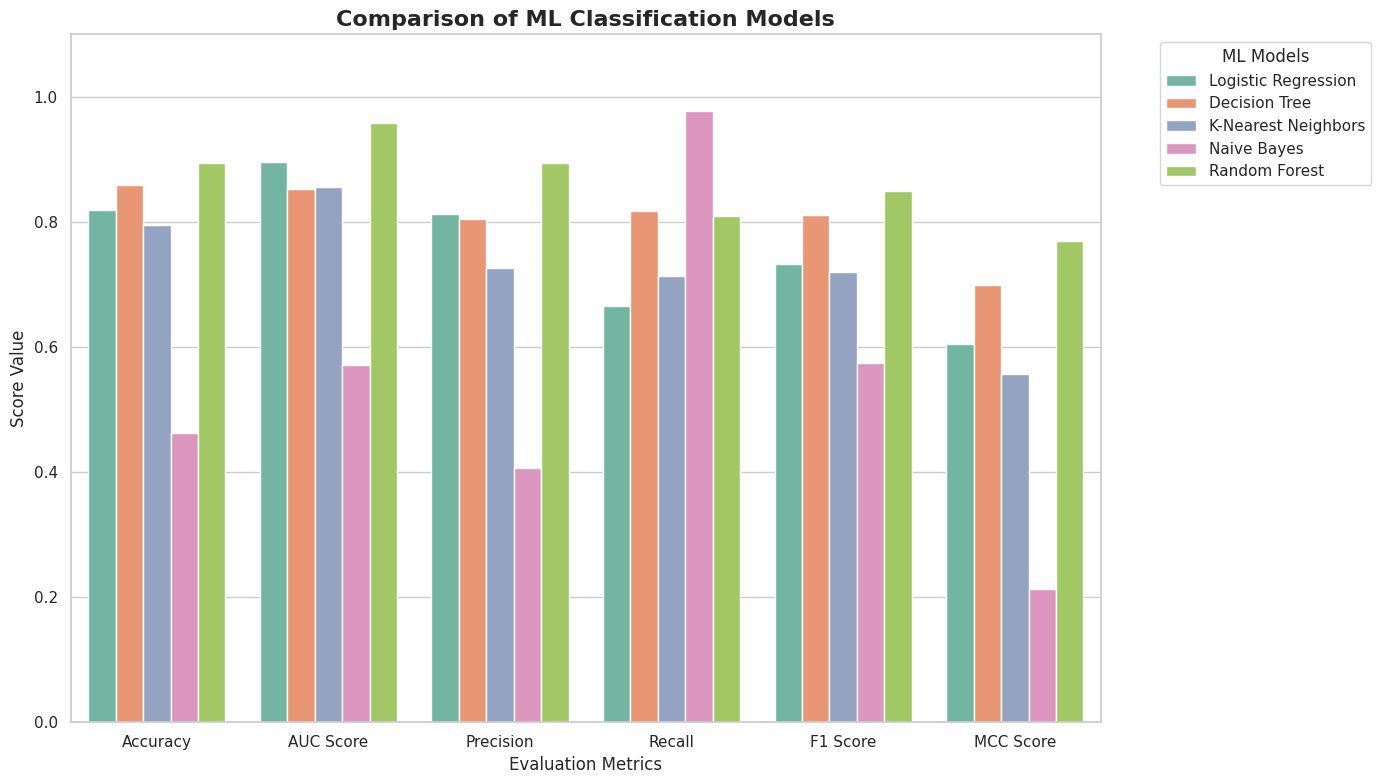

In [71]:
# Step 6: Visualizing the performance of the models (Graph Representation)
if 'df_results' in locals():
    plt.figure(figsize=(14, 8))

    # Prepare data for plotting
    df_plot = df_results.reset_index().rename(columns={'index': 'Model'})
    df_melted = pd.melt(df_plot, id_vars='Model', var_name='Metric', value_name='Score')

    sns.set_theme(style="whitegrid")
    ax = sns.barplot(x='Metric', y='Score', hue='Model', data=df_melted, palette='Set2')

    plt.title('Comparison of ML Classification Models', fontsize=16, fontweight='bold')
    plt.ylim(0, 1.1)
    plt.ylabel('Score Value', fontsize=12)
    plt.xlabel('Evaluation Metrics', fontsize=12)
    plt.legend(title='ML Models', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.savefig('model_comparison_chart.png', dpi=300)
    plt.show()

In [72]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Ensure df exists
if 'df' in locals():
    print("Initial Dataset Columns:", list(df.columns))

    # Target variable
    target = 'is_canceled'

    # Drop columns that leak target information or have extreme missingness
    # 'reservation_status' matches 'is_canceled' directly and must be dropped.
    # 'company' has ~94% missing values.
    # 'reservation_status_date' is a date field leaking status timing.
    cols_to_drop = ['reservation_status', 'reservation_status_date', 'company']
    df_clean = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

    # Split features and target
    X = df_clean.drop(columns=[target])
    y = df_clean[target]

    # Classify column types
    num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
    cat_cols = X.select_dtypes(include=['object']).columns.tolist()

    print(f"\nNumerical features ({len(num_cols)}):", num_cols)
    print(f"Categorical features ({len(cat_cols)}):", cat_cols)

    # Perform 80:20 Train-Test split maintaining class distribution (stratify=y)
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )
    print(f"\nTrain-Test Split complete!")
    print(f"Training set shape: {X_train_raw.shape}, Test set shape: {X_test_raw.shape}")

Initial Dataset Columns: ['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']

Numerical features (18): ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'days_in_waiting_list', 'adr', 'required_car_p

In [73]:
from sklearn.preprocessing import LabelEncoder

# Building Preprocessing Pipeline
# For Numerical: Impute with median, then scale
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# For Categorical: Impute with constant 'Unknown', then One-Hot encode
# We set handle_unknown='ignore' so unseen categories in test set don't break the pipeline
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

# Fit preprocessor only on training data and transform both sets
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

# Check post-processed shapes
print(f"Processed Training Set Shape: {X_train.shape}")
print(f"Processed Test Set Shape: {X_test.shape}")

Processed Training Set Shape: (95512, 252)
Processed Test Set Shape: (23878, 252)
